# CVRP (Time/Position-Indexed) → QUBO (Penalty Formulation)

This notebook teaches how to:

1. Define **time/position-indexed** Vehicle Routing Problem variables.
2. Write a constrained **Capacitated VRP (CVRP)** model using those variables.
3. Convert constraints into **QUBO penalties** (squared terms), including capacity using slack bits.
4. Build the full QUBO energy: **travel cost + penalties**.
5. Work a tiny numeric example, and expand at least one penalty symbolically.

---

## Big idea (intuitive)
- We have a **depot (0)** and **customers (1..n)**.
- Each vehicle picks an ordered sequence of stops.
- We model the sequence by **steps**: \(t=0,1,\dots,T\).
- QUBO needs **binary variables** and **one unconstrained quadratic objective**.
- So we **absorb constraints** into the objective via penalties.

We include a **dummy node** \(\emptyset\) to represent an unused step (route ended early).


In [1]:
# Imports
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import networkx as nx

np.set_printoptions(linewidth=120, suppress=True)


## 1) User controls (choose number of customers and vehicles)

You can set parameters manually below.

Optionally, if `ipywidgets` is available, an interactive UI will appear.


In [8]:
# --- User parameters (edit these) ---

n_customers = 5   # number of customers (nodes 1..n)
K = 2             # number of vehicles
Q_capacity = 5    # capacity per vehicle
T = None          # if None, uses T = n_customers (steps 0..T)
seed = 7          # RNG seed for generating an example cost matrix

# Demands: if None, random feasible-ish demands are generated
# Example: demands = [2, 3, 2] for n_customers=3

demands = None

# Penalty weights (rule-of-thumb starting points)
# You can tune these if constraint violations are showing up.

max_cost_hint = 10
lambdas = {
    "step": 10*max_cost_hint,
    "visit": 10*max_cost_hint,
    "start": 20*max_cost_hint,
    "no_depot_mid": 5*max_cost_hint,
    "contig": 20*max_cost_hint,
    "cap": 20*max_cost_hint,
}


In [71]:
# Optional interactive widgets
try:
    import ipywidgets as widgets
    from IPython.display import display

    ui = widgets.VBox([
        widgets.IntSlider(value=n_customers, min=1, max=100, step=1, description='n_customers'),
        widgets.IntSlider(value=K, min=1, max=8, step=1, description='K vehicles'),
        widgets.IntSlider(value=Q_capacity, min=1, max=30, step=1, description='Capacity Q'),
        widgets.IntSlider(value=seed, min=0, max=999, step=1, description='seed'),
    ])
    display(ui)

    def _update_params(change=None):
        global n_customers, K, Q_capacity, seed
        n_customers = ui.children[0].value
        K = ui.children[1].value
        Q_capacity = ui.children[2].value
        seed = ui.children[3].value

    for w in ui.children:
        w.observe(_update_params, names='value')

    print("Widgets loaded. Move sliders, then re-run the build cells below.")
except Exception:
    print("ipywidgets not available (that's OK). Use the manual parameters above.")


Widgets loaded. Move sliders, then re-run the build cells below.


## 2) Sets and notation

- Depot: node **0**
- Customers: $C = \{1,\dots,n\}$
- Dummy empty node: $\emptyset$
- Extended node set: $N = \{0\}\cup C \cup \{\emptyset\}$

Vehicles: $k\in\{1,\dots,K\}$

Steps: $t\in\{0,\dots,T\}$. We use $T=n$ if not specified.

Binary variable:
$
  x_{i,k,t}=1 \iff \text{vehicle }k\text{ is at node }i\text{ at step }t.
$

In [9]:
def build_sets(n_customers, T=None):
    if T is None:
        T = n_customers
    depot = 0
    customers = list(range(1, n_customers+1))
    empty = '∅'
    N = [depot] + customers + [empty]
    return depot, customers, empty, N, T


depot, C, EMPTY, N, T_eff = build_sets(n_customers, T)
print('Depot:', depot)
print('Customers:', C)
print('Empty symbol:', EMPTY)
print('N:', N)
print('T:', T_eff, '=> steps t=0..T')


Depot: 0
Customers: [1, 2, 3]
Empty symbol: ∅
N: [0, 1, 2, 3, '∅']
T: 3 => steps t=0..T


## 3) Example instance generator (costs and demands)

We need:
- travel costs $c_{ij}$
- demands $q_i$
- capacity $Q$

We'll generate a symmetric cost matrix using random 2D coordinates and Euclidean distance.
You can replace this with your own matrix if you want.


In [10]:
def generate_instance(n_customers, seed=0, demands=None, Q=10):
    rng = np.random.default_rng(seed)

    # coords for depot + customers (0..n)
    coords = rng.uniform(0, 10, size=(n_customers+1, 2))

    # distance matrix among depot+customers
    dist = np.linalg.norm(coords[:, None, :] - coords[None, :, :], axis=-1)

    # integer-ish costs
    c = np.rint(dist).astype(int)
    np.fill_diagonal(c, 0)

    if demands is None:
        # random demands in [1, floor(Q/2)]
        hi = max(1, Q//2)
        demands = rng.integers(1, hi+1, size=n_customers).tolist()
    else:
        demands = list(demands)

    q = {0: 0}
    for i, d in enumerate(demands, start=1):
        q[i] = int(d)
    q['∅'] = 0

    return c, coords, q

c_core, coords, q = generate_instance(n_customers, seed=seed, demands=demands, Q=Q_capacity)
print('Demands q_i:', {i: q[i] for i in [0]+C})
print('Capacity Q:', Q_capacity)
print('Cost matrix among depot+customers (0..n):', c_core)


Demands q_i: {0: 0, 1: 1, 2: 2, 3: 1}
Capacity Q: 5
Cost matrix among depot+customers (0..n): [[ 0  7  3  6]
 [ 7  0  8 10]
 [ 3  8  0  3]
 [ 6 10  3  0]]


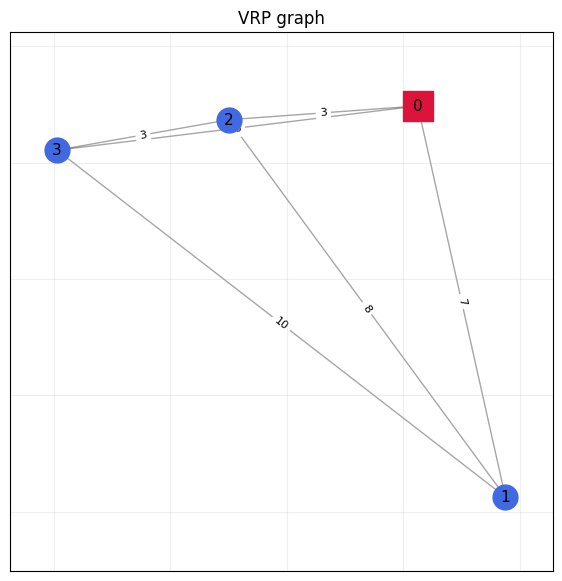

In [11]:
def draw_vrp_graph_networkx(coords, c_core, title="VRP graph",
                            k_nearest=None, cost_threshold=None,
                            show_weights=True, figsize=(7,7)):
    coords = np.asarray(coords)
    c = np.asarray(c_core)
    n_nodes = coords.shape[0]

    G = nx.Graph()
    for i in range(n_nodes):
        G.add_node(i, pos=(coords[i,0], coords[i,1]))

    # edges selection
    edges = set()
    for i in range(n_nodes):
        for j in range(i+1, n_nodes):
            if cost_threshold is None or c[i,j] <= cost_threshold:
                edges.add((i, j))

    for (i, j) in edges:
        G.add_edge(i, j, weight=int(c[i,j]))

    pos = {i: (coords[i,0], coords[i,1]) for i in range(n_nodes)}
    plt.figure(figsize=figsize)

    node_colors = ["crimson" if i==0 else "royalblue" for i in range(n_nodes)]
    node_shapes = {0: "s"}  # depot square

    # Draw customers and depot separately to give depot a different shape
    nx.draw_networkx_nodes(G, pos, nodelist=[0], node_color="crimson", node_shape="s", node_size=450)
    nx.draw_networkx_nodes(G, pos, nodelist=list(range(1, n_nodes)), node_color="royalblue", node_shape="o", node_size=320)

    nx.draw_networkx_edges(G, pos, alpha=0.35, width=1.0)
    nx.draw_networkx_labels(G, pos, font_size=11, font_color="black")

    if show_weights:
        edge_labels = {(u,v): d["weight"] for u,v,d in G.edges(data=True)}
        nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8)

    plt.title(title)
    plt.axis("equal")
    plt.grid(True, alpha=0.2)
    plt.show()

draw_vrp_graph_networkx(coords, c_core)

## 4) Variable indexing: map $x_{i,k,t}$ and slack bits into a single QUBO vector

A QUBO uses one big binary vector $z$. We'll map each variable to an index.

### Slack bits for capacity
For each vehicle $k$, add slack $s_k$ so that:
$$
\sum_{t=1}^{T}\sum_{i\in C} q_i x_{i,k,t} + s_k = Q
$$
Encode slack in binary:
$$
 s_k = \sum_{b=0}^{B-1}2^b\,w_{k,b}
$$
where $B=\lceil\log_2(Q+1)\rceil$.


In [12]:
import math

def variable_indexing(N, K, T, Q):
    # Index for x_{i,k,t}
    x_index = {}
    idx = 0
    for k in range(1, K+1):
        for t in range(0, T+1):
            for i in N:
                x_index[(i,k,t)] = idx
                idx += 1

    # Slack bits w_{k,b}
    B = int(math.ceil(math.log2(Q+1)))
    w_index = {}
    for k in range(1, K+1):
        for b in range(B):
            w_index[(k,b)] = idx
            idx += 1

    return x_index, w_index, idx, B

x_index, w_index, n_vars, B = variable_indexing(N, K, T_eff, Q_capacity)
print('Total binary variables:', n_vars)
print('x variables:', len(x_index), ' = |N|*K*(T+1) =', len(N)*K*(T_eff+1))
print('Slack bits per vehicle B:', B, ' => total slack bits:', len(w_index))


Total binary variables: 69
x variables: 60  = |N|*K*(T+1) = 60
Slack bits per vehicle B: 3  => total slack bits: 9


## 5) QUBO construction helpers

We construct an energy:
$$
H(z) = z^T Q z + \text{constant}
$$

We use helper functions to add:
- linear terms $a z_i$ (store as diagonal)
- quadratic terms $b z_i z_j$ (store in upper triangle)
- squared penalties of affine expressions $(\sum a_i z_i + c)^2$


In [118]:
def add_quadratic(Qmat, i, j, coeff):
    # Store in upper triangle
    if i <= j:
        Qmat[i, j] += coeff
    else:
        Qmat[j, i] += coeff


def add_linear(Qmat, i, coeff):
    # Linear coeff*z_i stored on diagonal
    Qmat[i, i] += coeff


def square_of_affine_to_qubo(Qmat, var_coeffs, constant, weight=1.0):
    # Adds weight*(sum_i a_i z_i + constant)^2
    # Expansion: weight*( z^T (a a^T) z + 2*constant*(a^T z) + constant^2 )
    # For binary z, keep all terms in QUBO form.

    items = list(var_coeffs.items())

    # Quadratic + diagonal from (a^T z)^2
    for p, (i, ai) in enumerate(items):
        add_linear(Qmat, i, weight * (ai * ai))  # ai^2 z_i
        for j, aj in items[p+1:]:
            add_quadratic(Qmat, i, j, weight * (2 * ai * aj))

    # Linear from 2*constant*(a^T z)
    for i, ai in items:
        add_linear(Qmat, i, weight * (2 * constant * ai))

    # Constant contribution
    return weight * (constant * constant)


## 6) Build the full QUBO (cost + penalties)

### Conventions used
- Start at depot: enforce $x_{0,k,0}=1$ using a penalty.
- Forbid depot at steps $t\ge1$ (optional) via a linear penalty.
- Use $\emptyset$ for unused steps.
- Enforce contiguity: once $\emptyset$, always $\emptyset$.
- Add return-to-depot cost when transitioning into $\emptyset$.


In [119]:
def build_qubo(n_customers, K, Q_capacity, seed=0, T=None, demands=None, lambdas=None):
    depot, C, EMPTY, N, T = build_sets(n_customers, T)
    c_core, coords, q = generate_instance(n_customers, seed=seed, demands=demands, Q=Q_capacity)

    x_index, w_index, n_vars, B = variable_indexing(N, K, T, Q_capacity)
    Qmat = np.zeros((n_vars, n_vars), dtype=float)
    const = 0.0

    # Cost function on N: define costs to/from EMPTY as 0
    def cost(i, j):
        if i == EMPTY or j == EMPTY:
            return 0.0
        return float(c_core[int(i), int(j)])

    # 6.1 Travel cost for consecutive steps t -> t+1
    for k in range(1, K+1):
        for t in range(0, T):
            for i in N:
                for j in N:
                    if j == i:
                        continue
                    cij = cost(i, j)
                    if cij != 0:
                        ii = x_index[(i,k,t)]
                        jj = x_index[(j,k,t+1)]
                        add_quadratic(Qmat, ii, jj, cij)

    # 6.2 Return-to-depot when transitioning into EMPTY
    for k in range(1, K+1):
        for t in range(0, T):
            for i in [depot] + C:
                ci0 = cost(i, depot)
                if ci0 != 0:
                    ii = x_index[(i,k,t)]
                    jj = x_index[(EMPTY,k,t+1)]
                    add_quadratic(Qmat, ii, jj, ci0)

    # Default lambdas if none provided
    if lambdas is None:
        max_c = np.max(c_core)
        lambdas = {
            "step": 10*max_c,
            "visit": 10*max_c,
            "start": 20*max_c,
            "no_depot_mid": 5*max_c,
            "contig": 20*max_c,
            "cap": 20*max_c,
        }

    # 6.3 One node per step: (sum_i x_{i,k,t} - 1)^2
    for k in range(1, K+1):
        for t in range(0, T+1):
            var_coeffs = {x_index[(i,k,t)]: 1.0 for i in N}
            const += square_of_affine_to_qubo(Qmat, var_coeffs, constant=-1.0, weight=lambdas["step"])

    # 6.4 Each customer visited exactly once: (sum_{k,t} x_{i,k,t} - 1)^2
    for i in C:
        var_coeffs = {x_index[(i,k,t)]: 1.0 for k in range(1, K+1) for t in range(1, T+1)}
        const += square_of_affine_to_qubo(Qmat, var_coeffs, constant=-1.0, weight=lambdas["visit"])

    # 6.5 Start depot penalty: (x_{0,k,0} - 1)^2
    for k in range(1, K+1):
        var_coeffs = {x_index[(depot,k,0)]: 1.0}
        const += square_of_affine_to_qubo(Qmat, var_coeffs, constant=-1.0, weight=lambdas["start"])

    # 6.6 Forbid depot at steps 1..T (linear)
    for k in range(1, K+1):
        for t in range(1, T+1):
            add_linear(Qmat, x_index[(depot,k,t)], lambdas["no_depot_mid"])

    # 6.7 Contiguity of EMPTY: penalize x_EMPTY(k,t)=1 and x_EMPTY(k,t+1)=0
    # Penalty term: lambda * x_t*(1 - x_{t+1}) = lambda*x_t - lambda*x_t*x_{t+1}
    for k in range(1, K+1):
        for t in range(0, T):
            xt = x_index[(EMPTY,k,t)]
            xt1 = x_index[(EMPTY,k,t+1)]
            add_linear(Qmat, xt, lambdas["contig"])
            add_quadratic(Qmat, xt, xt1, -lambdas["contig"])

    # 6.8 Capacity with slack bits: (sum q_i x_{i,k,t} + sum 2^b w_{k,b} - Q)^2
    for k in range(1, K+1):
        var_coeffs = {}

        # Load terms: t=1..T
        for t in range(1, T+1):
            for i in C:
                idx = x_index[(i,k,t)]
                var_coeffs[idx] = var_coeffs.get(idx, 0.0) + q[i]

        # Slack bits
        for b in range(B):
            idx = w_index[(k,b)]
            var_coeffs[idx] = var_coeffs.get(idx, 0.0) + (2**b)

        const += square_of_affine_to_qubo(Qmat, var_coeffs, constant=-Q_capacity, weight=lambdas["cap"])

    info = {
        "depot": depot,
        "customers": C,
        "EMPTY": EMPTY,
        "N": N,
        "T": T,
        "Q": Q_capacity,
        "q": q,
        "coords": coords,
        "c_core": c_core,
        "x_index": x_index,
        "w_index": w_index,
        "B": B,
        "n_vars": n_vars,
        "lambdas": lambdas,
    }

    return Qmat, const, info


Qmat, const, info = build_qubo(n_customers, K, Q_capacity, seed=seed, T=T, demands=demands, lambdas=lambdas)
print('Built QUBO with', info['n_vars'], 'variables.')
print('Constant offset:', const)
print('Max |Q| coeff:', np.max(np.abs(Qmat)))


Built QUBO with 45 variables.
Constant offset: 6300.0
Max |Q| coeff: 4800.0


## 7) Energy + constraint checking

These helpers let you:
- build a bitvector \(z\) from a human-readable assignment
- compute energy \(H(z)\)
- check if constraints are satisfied


In [120]:
def energy(Qmat, z, const=0.0):
    z = np.asarray(z).astype(float)
    return float(z @ Qmat @ z + const)


def make_z_from_assignment(info, x_assign=None, w_assign=None):
    # x_assign: dict {(i,k,t):0/1}
    # w_assign: dict {(k,b):0/1}
    z = np.zeros(info['n_vars'], dtype=int)
    if x_assign:
        for key, val in x_assign.items():
            z[info['x_index'][key]] = int(val)
    if w_assign:
        for key, val in w_assign.items():
            z[info['w_index'][key]] = int(val)
    return z


def check_constraints(info, x_assign):
    depot = info['depot']
    C = info['customers']
    EMPTY = info['EMPTY']
    N = info['N']
    T = info['T']
    q = info['q']
    Qcap = info['Q']
    K = max(k for (_,k,_) in info['x_index'].keys())

    # (1) One node per step
    step_ok = True
    step_viol = []
    for k in range(1, K+1):
        for t in range(0, T+1):
            s = sum(x_assign.get((i,k,t),0) for i in N)
            if s != 1:
                step_ok = False
                step_viol.append((k,t,s))

    # (2) Each customer exactly once
    visit_ok = True
    visit_viol = []
    for i in C:
        s = sum(x_assign.get((i,k,t),0) for k in range(1, K+1) for t in range(1, T+1))
        if s != 1:
            visit_ok = False
            visit_viol.append((i,s))

    # (3) Start depot
    start_ok = True
    start_viol = []
    for k in range(1, K+1):
        if x_assign.get((depot,k,0),0) != 1:
            start_ok = False
            start_viol.append(k)

    # (4) Depot not in mid steps
    depotmid_ok = True
    depotmid_viol = []
    for k in range(1, K+1):
        for t in range(1, T+1):
            if x_assign.get((depot,k,t),0) == 1:
                depotmid_ok = False
                depotmid_viol.append((k,t))

    # (5) Contiguity of EMPTY
    contig_ok = True
    contig_viol = []
    for k in range(1, K+1):
        for t in range(0, T):
            if x_assign.get((EMPTY,k,t),0)==1 and x_assign.get((EMPTY,k,t+1),0)==0:
                contig_ok = False
                contig_viol.append((k,t))

    # (6) Capacity
    cap_ok = True
    cap_viol = []
    for k in range(1, K+1):
        load = sum(q[i]*x_assign.get((i,k,t),0) for i in C for t in range(1, T+1))
        if load > Qcap:
            cap_ok = False
            cap_viol.append((k, load))

    return {
        'step_ok': step_ok, 'step_viol': step_viol,
        'visit_ok': visit_ok, 'visit_viol': visit_viol,
        'start_ok': start_ok, 'start_viol': start_viol,
        'depotmid_ok': depotmid_ok, 'depotmid_viol': depotmid_viol,
        'contig_ok': contig_ok, 'contig_viol': contig_viol,
        'cap_ok': cap_ok, 'cap_viol': cap_viol,
    }


## 8) Build a simple feasible assignment (greedy)

This is **not an optimizer**. It just constructs a feasible-ish assignment to test that the QUBO behaves sensibly.


In [121]:
def greedy_feasible_assignment(info):
    depot = info['depot']
    C = info['customers']
    EMPTY = info['EMPTY']
    N = info['N']
    T = info['T']
    q = info['q']
    Qcap = info['Q']
    K = max(k for (_,k,_) in info['x_index'].keys())

    # Assign customers to vehicles greedily by capacity
    vehicle_customers = {k: [] for k in range(1, K+1)}
    loads = {k: 0 for k in range(1, K+1)}

    for cust in C:
        placed = False
        for kk in range(1, K+1):
            if loads[kk] + q[cust] <= Qcap:
                vehicle_customers[kk].append(cust)
                loads[kk] += q[cust]
                placed = True
                break
        if not placed:
            # if impossible, force into last vehicle (will violate capacity)
            vehicle_customers[K].append(cust)
            loads[K] += q[cust]

    # Build x assignment
    x = {}
    for k in range(1, K+1):
        # step 0: depot
        for i in N:
            x[(i,k,0)] = 1 if i==depot else 0

        # steps 1..T: customers then EMPTY
        seq = vehicle_customers[k]
        for t in range(1, T+1):
            node = seq[t-1] if t-1 < len(seq) else EMPTY
            for i in N:
                x[(i,k,t)] = 1 if i==node else 0

    # Choose slack bits for capacity equality (if slack negative, clamp to 0)
    w = {}
    B = info['B']
    for k in range(1, K+1):
        load = sum(q[i]*x[(i,k,t)] for i in C for t in range(1, T+1))
        slack = info['Q'] - load
        if slack < 0:
            slack = 0
        for b in range(B):
            w[(k,b)] = 1 if (slack >> b) & 1 else 0

    return x, w, vehicle_customers, loads

x_feas, w_feas, veh_cust, loads = greedy_feasible_assignment(info)
print('Greedy split:', veh_cust)
print('Loads:', loads)
viol = check_constraints(info, x_feas)
print('Constraint OK flags:', {k:v for k,v in viol.items() if k.endswith('_ok')})

z_feas = make_z_from_assignment(info, x_feas, w_feas)
print('Energy of greedy assignment:', energy(Qmat, z_feas, const))


Greedy split: {1: [1, 2, 3, 4, 5]}
Loads: {1: 6}
Constraint OK flags: {'step_ok': True, 'visit_ok': True, 'start_ok': True, 'depotmid_ok': True, 'contig_ok': True, 'cap_ok': False}
Energy of greedy assignment: 229.0


## 9) Symbolic algebra (SymPy): expand one penalty

We'll expand:
$
(\sum_{i\in N} x_i - 1)^2
$

This reveals explicit linear and quadratic terms.

> Keep `n_customers` small if you want to view large expansions.


In [122]:
def sympy_expand_step_penalty(N_labels):
    # Build sympy symbols for one step (we ignore k,t in names here)
    names = []
    for i in N_labels:
        if i == '∅':
            names.append('x_empty')
        else:
            names.append(f'x_{i}')
    xs = sp.symbols(' '.join(names))
    expr = (sum(xs) - 1)**2
    return xs, sp.expand(expr)

xs, expanded = sympy_expand_step_penalty(info['N'])
print('Symbols:', xs)
print('Expanded (sum x - 1)^2 =')
sp.pprint(expanded)

Symbols: (x_0, x_1, x_2, x_3, x_4, x_5, x_empty)
Expanded (sum x - 1)^2 =
  2                                                                            ↪
x₀  + 2⋅x₀⋅x₁ + 2⋅x₀⋅x₂ + 2⋅x₀⋅x₃ + 2⋅x₀⋅x₄ + 2⋅x₀⋅x₅ + 2⋅x₀⋅x_empty - 2⋅x₀ +  ↪

↪   2                                                                   2      ↪
↪ x₁  + 2⋅x₁⋅x₂ + 2⋅x₁⋅x₃ + 2⋅x₁⋅x₄ + 2⋅x₁⋅x₅ + 2⋅x₁⋅x_empty - 2⋅x₁ + x₂  + 2⋅ ↪

↪                                                     2                        ↪
↪ x₂⋅x₃ + 2⋅x₂⋅x₄ + 2⋅x₂⋅x₅ + 2⋅x₂⋅x_empty - 2⋅x₂ + x₃  + 2⋅x₃⋅x₄ + 2⋅x₃⋅x₅ +  ↪

↪                         2                                     2              ↪
↪ 2⋅x₃⋅x_empty - 2⋅x₃ + x₄  + 2⋅x₄⋅x₅ + 2⋅x₄⋅x_empty - 2⋅x₄ + x₅  + 2⋅x₅⋅x_emp ↪

↪                    2                
↪ ty - 2⋅x₅ + x_empty  - 2⋅x_empty + 1


## 10) QUBO stats

We compute how many coefficients are non-zero (upper triangle) and the coefficient scale.


In [123]:
def qubo_stats(Qmat):
    tri = np.triu(Qmat)
    nnz = np.count_nonzero(np.abs(tri) > 1e-12)
    n = Qmat.shape[0]
    total = n*(n+1)//2
    density = nnz/total
    return {
        'n_vars': n,
        'nnz_upper': int(nnz),
        'density_upper': float(density),
        'max_abs_coeff': float(np.max(np.abs(Qmat)))
    }

qubo_stats(Qmat)

{'n_vars': 45,
 'nnz_upper': 599,
 'density_upper': 0.578743961352657,
 'max_abs_coeff': 4800.0}

## 11) Compare with a random bitstring (usually infeasible)

This shows why penalties are needed.


In [124]:
rng = np.random.default_rng(seed+1)
z_rand = rng.integers(0, 2, size=info['n_vars'])
print('Random energy:', energy(Qmat, z_rand, const))
print('Greedy energy:', energy(Qmat, z_feas, const))

Random energy: 58917.0
Greedy energy: 229.0


In [125]:

import numpy as np

def qubo_to_ising_from_xTQx(Q, const=0.0, tol=1e-12):
    """
    Convert a QUBO given as E(x)=x^T Q x + const into Ising:
      E(s)= sum_i h_i s_i + sum_{i<j} J_ij s_i s_j + offset
    using mapping x_i = (1 - s_i)/2.
    
    Works whether Q is upper-triangular (as in your notebook) or symmetric/full.
    """
    Q = np.asarray(Q, dtype=float)
    n = Q.shape[0]
    assert Q.shape == (n, n), "Q must be square."

    # Fold to canonical pair coefficients for x_i x_j:
    # In x^T Q x, the coefficient on x_i x_j (i<j) is Q[i,j] + Q[j,i].
    Qc = np.zeros_like(Q)
    np.fill_diagonal(Qc, np.diag(Q))
    for i in range(n):
        for j in range(i+1, n):
            Qc[i, j] = Q[i, j] + Q[j, i]

    h = np.zeros(n, dtype=float)
    J = np.zeros((n, n), dtype=float)
    offset = float(const)

    # Diagonal terms: Qii x_i with x_i=(1-s_i)/2 => +Qii/2 to offset, -Qii/2 to h_i
    for i in range(n):
        Qii = Qc[i, i]
        if abs(Qii) > tol:
            offset += Qii / 2.0
            h[i] += -Qii / 2.0

    # Off-diagonal: Qij x_i x_j with x_i x_j=(1 - s_i - s_j + s_i s_j)/4
    for i in range(n):
        for j in range(i+1, n):
            Qij = Qc[i, j]
            if abs(Qij) > tol:
                offset += Qij / 4.0
                h[i] += -Qij / 4.0
                h[j] += -Qij / 4.0
                J[i, j] += Qij / 4.0  # store upper triangle

    # Convert to sparse dicts for readability
    h_dict = {i: float(h[i]) for i in range(n) if abs(h[i]) > tol}
    J_dict = {(i, j): float(J[i, j]) for i in range(n) for j in range(i+1, n) if abs(J[i, j]) > tol}
    return h_dict, J_dict, offset


# --- Use with your notebook variables ---
h, J, offset = qubo_to_ising_from_xTQx(Qmat, const=const)

print("Number of qubits:", Qmat.shape[0])
print("offset =", offset)
print("\nFirst few h_i terms:")
for i, v in list(h.items())[:10]:
    print(f"  h[{i}] = {v}")

print("\nFirst few J_ij terms:")
for (i, j), v in list(J.items())[:10]:
    print(f"  J[{i},{j}] = {v}")

Number of qubits: 45
offset = 46747.5

First few h_i terms:
  h[0] = -157.0
  h[1] = -259.5
  h[2] = -256.75
  h[3] = -255.5
  h[4] = -258.25
  h[5] = -257.5
  h[6] = -300.0
  h[7] = -289.0
  h[8] = -3117.0
  h[9] = -3112.25

First few J_ij terms:
  J[0,1] = 50.0
  J[0,2] = 50.0
  J[0,3] = 50.0
  J[0,4] = 50.0
  J[0,5] = 50.0
  J[0,6] = 50.0
  J[0,8] = 2.0
  J[0,9] = 1.25
  J[0,10] = 0.75
  J[0,11] = 1.5


In [126]:
import sympy as sp

def ising_to_symbolic_pauliZ(h, J, offset, n_qubits):
    I = sp.Symbol("I")
    Z = [sp.Symbol(f"Z{i}") for i in range(n_qubits)]
    expr = offset * I

    for i, hi in h.items():
        expr += hi * Z[i]
    for (i, j), Jij in J.items():
        expr += Jij * Z[i] * Z[j]
    return sp.simplify(expr)

H_expr = ising_to_symbolic_pauliZ(h, J, offset, n_qubits=Qmat.shape[0])
sp.pprint(H_expr)

46747.5⋅I + 50.0⋅Z₀⋅Z₁ + 0.75⋅Z₀⋅Z₁₀ + 1.5⋅Z₀⋅Z₁₁ + 1.5⋅Z₀⋅Z₁₂ + 50.0⋅Z₀⋅Z₂ +  ↪

↪ 50.0⋅Z₀⋅Z₃ + 50.0⋅Z₀⋅Z₄ + 50.0⋅Z₀⋅Z₅ + 50.0⋅Z₀⋅Z₆ + 2.0⋅Z₀⋅Z₈ + 1.25⋅Z₀⋅Z₉ - ↪

↪  157.0⋅Z₀ + 1.5⋅Z₁⋅Z₁₀ + 0.5⋅Z₁⋅Z₁₁ + 1.75⋅Z₁⋅Z₁₂ + 2.0⋅Z₁⋅Z₁₃ + 50.0⋅Z₁⋅Z₂  ↪

↪ + 50.0⋅Z₁⋅Z₃ + 50.0⋅Z₁⋅Z₄ + 50.0⋅Z₁⋅Z₅ + 50.0⋅Z₁⋅Z₆ + 2.0⋅Z₁⋅Z₇ + 1.75⋅Z₁⋅Z₉ ↪

↪  - 259.5⋅Z₁ + 250.0⋅Z₁₀⋅Z₁₁ + 250.0⋅Z₁₀⋅Z₁₂ + 50.0⋅Z₁₀⋅Z₁₃ + 0.75⋅Z₁₀⋅Z₁₄ +  ↪

↪ 201.5⋅Z₁₀⋅Z₁₅ + 200.5⋅Z₁₀⋅Z₁₆ + 450.0⋅Z₁₀⋅Z₁₇ + 201.25⋅Z₁₀⋅Z₁₈ + 200.75⋅Z₁₀⋅ ↪

↪ Z₁₉ + 0.5⋅Z₁₀⋅Z₂ + 0.75⋅Z₁₀⋅Z₂₀ + 200.0⋅Z₁₀⋅Z₂₂ + 200.0⋅Z₁₀⋅Z₂₃ + 450.0⋅Z₁₀⋅ ↪

↪ Z₂₄ + 200.0⋅Z₁₀⋅Z₂₅ + 200.0⋅Z₁₀⋅Z₂₆ + 200.0⋅Z₁₀⋅Z₂₉ + 200.0⋅Z₁₀⋅Z₃₀ + 450.0⋅ ↪

↪ Z₁₀⋅Z₃₁ + 200.0⋅Z₁₀⋅Z₃₂ + 200.0⋅Z₁₀⋅Z₃₃ + 200.0⋅Z₁₀⋅Z₃₆ + 200.0⋅Z₁₀⋅Z₃₇ + 45 ↪

↪ 0.0⋅Z₁₀⋅Z₃₈ + 200.0⋅Z₁₀⋅Z₃₉ + 1.25⋅Z₁₀⋅Z₄ + 200.0⋅Z₁₀⋅Z₄₀ + 200.0⋅Z₁₀⋅Z₄₂ +  ↪

↪ 400.0⋅Z₁₀⋅Z₄₃ + 800.0⋅Z₁₀⋅Z₄₄ + 0.75⋅Z₁₀⋅Z₅ + 50.0⋅Z₁₀⋅Z₇ + 250.0⋅Z₁₀⋅Z₈ + 2 ↪

↪ 50.0⋅Z₁₀⋅Z₉ - 5810.25⋅Z₁₀ + 150.0⋅Z₁₁⋅Z₁₂ + 50.0⋅Z₁₁⋅Z₁₃ + 1.5⋅Z₁₁⋅Z₁₄ + 100 ↪

↪ .5⋅Z₁₁⋅Z₁₅ + 1

In [127]:
def qubo_energy(Q, x, const=0.0):
    x = np.asarray(x, dtype=float)
    return float(x @ Q @ x + const)

def ising_energy(h, J, s, offset=0.0):
    E = offset
    for i, hi in h.items():
        E += hi * s[i]
    for (i, j), Jij in J.items():
        E += Jij * s[i] * s[j]
    return float(E)

rng = np.random.default_rng(0)
n = Qmat.shape[0]
x = rng.integers(0, 2, size=n)
s = 1 - 2*x  # s_i = 1 - 2 x_i

print("QUBO:", qubo_energy(Qmat, x, const))
print("Ising:", ising_energy(h, J, s, offset))

QUBO: 38062.0
Ising: 38062.0


# 12) Exploring Solution

Find optimal solution by exhaustive search and check candidate solutions against it.

## Solve by Brute Force

In [ ]:
import numpy as np
from itertools import product

def brute_force_maxcut(Q):
    n = len(Q)
    best_x = None
    best_val = -np.inf
    
    for bits in product([0, 1], repeat=n):
        x = np.array(bits)
        val = x @ Q @ x
        if val > best_val:
            best_val = val
            best_x = x
    
    return best_x, best_val

# Find optimal
opt_x, opt_val = brute_force_maxcut(-Qmat)
print(f"Optimal value: {opt_val}")

## Check Solution

In [ ]:
def check_solution(x, Q, maxcut=True):
    x = np.array(x)
    if maxcut:
        if x[-1] == 1: 
            x = 1 - x[:-1]
        else: 
            x = x[:-1]
    return x @ Q @ x

check_solution(np.array([0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1]), -Qmat)

# 13) QUBO to Max-Cut Reduction

We convert a QUBO problem

$$
\max_{x \in \{0,1\}^n} x^T Q x
$$

into an equivalent **Max-Cut** problem on a graph with **$n+1$ vertices**. This transformation follows the construction proposed by Bhattacharyya *et al.* (2025), where an auxiliary vertex is introduced to eliminate the linear terms that appear when mapping binary variables $\{0,1\}$ into Ising spins $\{-1,1\}$.

The adjacency matrix $A$ of the Max-Cut graph is constructed from the QUBO matrix $Q$ as

$$
A_{i,j} = -Q_{i,j}, \quad
A_{n,i} = \sum_{j=0}^{n-1} Q_{i,j}, \quad
A_{n,n} = 0.
$$

Solving the Max-Cut problem on this graph is energetically equivalent to solving the original QUBO. The extra vertex (the last one) is an auxiliary node introduced by the reduction and plays a special role in warm-start QAOA methods.


In [ ]:
def normalize_qubo(Q):
    Q = np.array(Q, dtype=float)
    max_abs = np.max(np.abs(Q))
    if max_abs > 0:
        Q = Q / max_abs
    return Q

def qubo_to_maxcut_matrix(Q):
    """
    Convert QUBO matrix Q (n x n) to Max-Cut adjacency matrix A (n+1 x n+1)
    following the paper mapping.
    """
    n = Q.shape[0]
    A = np.zeros((n+1, n+1))

    # Edges between original variables
    for i in range(n):
        for j in range(i+1, n):
            A[i, j] = A[j, i] = -Q[i, j]

    # Edges to auxiliary node
    row_sums = Q.sum(axis=1)
    for i in range(n):
        A[i, n] = A[n, i] = row_sums[i]

    np.fill_diagonal(A, 0)
    return A

# Step 1: normalize QUBO
Q_sym = (Qmat + Qmat.T) / 2.0
Qmax = -Q_sym
Q_norm = normalize_qubo(Qmax)

# Step 2: build MaxCut matrix
A = qubo_to_maxcut_matrix(Q_norm)

print("Matrix A shape:", A.shape)

This cell converts the adjacency matrix we created earlier to JSON format.

In [ ]:
import json

def adjacency_matrix_to_json(A, filename="graph.json"):
    """
    Converts a weighted adjacency matrix to JSON-compatible format.

    Parameters:
    -----------
    A : list of list or np.ndarray
        n x n adjacency matrix, where A[i][j] is the weight of edge (i, j).
        If A[i][j] = 0, no edge is created (unless zero weights are valid).
        Matrix is assumed symmetric for undirected graphs.
    filename : str
        Output file name.
    """
    n = len(A)
    
    # Create list of nodes
    nodes = [{"id": i} for i in range(n)]
    
    # Create list of edges (links)
    links = []
    for i in range(n):
        # For undirected graphs, only traverse j > i to avoid duplication
        for j in range(i + 1, n):
            weight = A[i][j]
            # If you want to include edges with weight 0, remove the condition below
            if weight != 0:
                links.append({
                    "weight": float(weight),
                    "source": i,
                    "target": j
                })
    
    # Build final dictionary
    graph_data = {
        "directed": False,
        "multigraph": False,
        "graph": {},
        "nodes": nodes,
        "links": links
    }
    
    # Save to JSON file
    with open(filename, 'w', encoding='utf-8') as f:
        json.dump(graph_data, f, indent=2, ensure_ascii=False)
    
    print(f"File saved as {filename}")
    return graph_data
    
# Convert and save
result = adjacency_matrix_to_json(A, "problem_graph_2.json")